# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [3]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [4]:

%matplotlib inline
sys.path.append("..")

import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [133]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.05

# Bubble dynamcis parameters
R_init = 10e-6
frequency = 10e5
pac = -.02e6

# Parameters for FFT plot
fft_lim = 10 * frequency

# Parameters for the wavelet transform
wavelet = "db4"
levels = 5  # set to none to use max-level transform
mode = "symmetric"
use_min_entropy = False
min_level = 1

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [134]:
# generate sound wave
data, t_plot = train.get_data(R_init, frequency, pac, sampling_rate, return_time=True)
data = (data - np.average(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
# data = data[:int(len(data) / 2)]
# t_plot = t_plot[:len(data)]
data *= np.blackman(len(data))
signal_length = len(data)

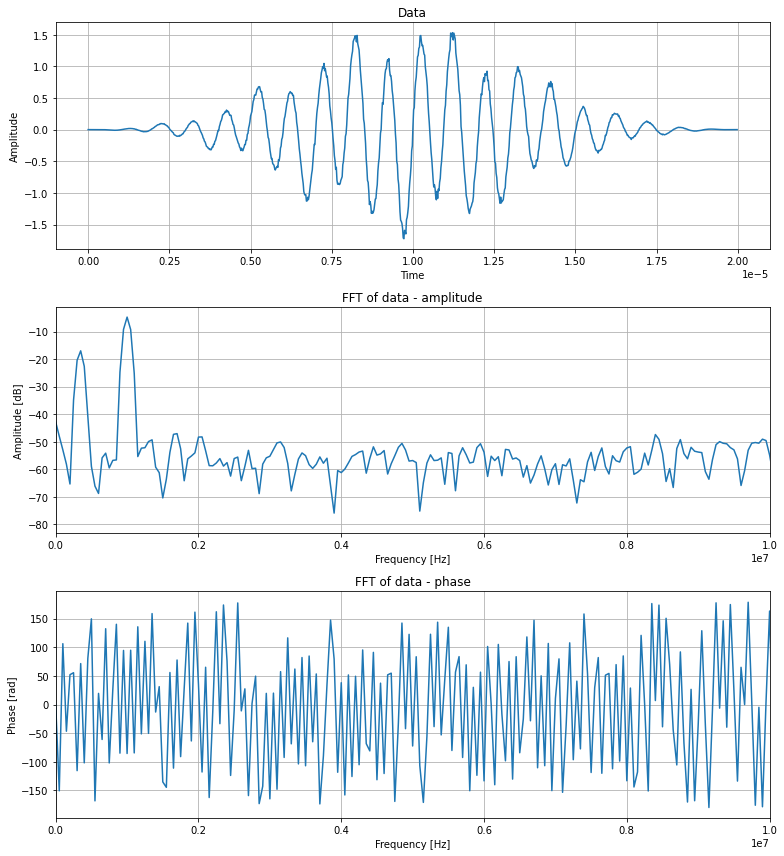

In [135]:
# Plot generated data
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    20*np.log10(np.abs(fft_data))
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

Wavelet transform

In [136]:
wpt_df, tr_ob = train.generate_training_data(
    data, levels, wavelet, mode, 
    include_tr_ob=True, min_entropy=use_min_entropy,
    min_level=min_level
)

In [137]:
tr_ob.calc_frequencies(sampling_rate)
tr_ob.info(leaf_nodes=True)

,level,node number,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,5,0,"(0.0, 7.812e5)",390625.0,48.685123,1.687396,1.281187,0.107613,6.555296,3.506594,0.462684,0.462684,2.160886,3.688551,0.633900
1,5,1,"(7.812e5, 1.562e6)",1171875.0,241.652222,2.383191,6.359269,0.803407,4.314111,2.147748,-0.359371,0.359371,2.423853,2.760598,2.094092
2,5,3,"(1.562e6, 2.344e6)",1953125.0,14.760074,1.169089,0.388423,-0.410695,4.196316,2.242370,-0.334112,0.334112,2.437185,2.759894,0.262725
3,5,2,"(2.344e6, 3.125e6)",2734375.0,1.631784,0.212663,0.042942,-1.367121,4.370278,2.451266,-0.111326,0.111326,2.420549,2.786722,0.040643
4,5,6,"(3.125e6, 3.906e6)",3515625.0,0.026092,-1.583485,0.000687,-3.163268,5.436973,0.659057,-1.742264,1.742264,2.042698,4.297288,0.000969
5,5,7,"(3.906e6, 4.688e6)",4296875.0,0.035885,-1.445088,0.000944,-3.024871,6.136997,3.035799,0.090833,0.090833,2.159060,4.732055,0.001309
6,5,5,"(4.688e6, 5.469e6)",5078125.0,0.122729,-0.911054,0.003230,-2.490837,5.287343,3.084246,0.530935,0.530935,2.264560,3.422067,0.004027
7,5,4,"(5.469e6, 6.25e6)",5859375.0,0.032193,-1.492239,0.000847,-3.072022,5.224307,2.290829,-0.890203,0.890203,2.299424,4.474940,0.001200
8,5,12,"(6.25e6, 7.031e6)",6640625.0,0.023981,-1.620136,0.000631,-3.199920,7.167365,3.304290,0.098787,0.098787,2.030230,4.733022,0.000896
9,5,13,"(7.031e6, 7.812e6)",7421875.0,0.016709,-1.777046,0.000440,-3.356830,3.582553,2.241442,-0.185605,0.185605,2.474726,4.008542,0.000668


In [138]:
# ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.15))
# ax_df2.spines['right'].set_edgecolor('green')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.3))
# ax_df2.spines['right'].set_edgecolor('cyan')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest factor',c='cyan')

In [139]:
# ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest factor',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [140]:
# tr_ob.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_ob, max(t_plot))

In [141]:
# wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [142]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [143]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training k-means algorithm
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

def train_k_means(wpt_df, classifying_metrics, *, no_clusters=None, use_pca=False):
    """
    Trains a k-means algorithm based on a set of training data given by wpt_df and classifying metrics
    no_clusters can be kept at None to choose an optimal number of clusters by silhouette score.
    use_pca can be set to True to apply pca to the normalised data set before training the algorithm.

    """
    data_train = wpt_df[classifying_metrics]

    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    if use_pca is True:
        pca = PCA(n_components=2)
        data_train_normalised = pca.fit_transform(data_train_normalised)    

    if no_clusters is not None:
        kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
        labels = kmeans.fit_predict(data_train_normalised)
    else:
        algorithms = []
        for no_clusters in range(2, 5):
            kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
            labels = kmeans.fit_predict(data_train_normalised)
            silhouette_score = metrics.silhouette_score(data_train_normalised, labels)
            algorithms.append((silhouette_score, kmeans, labels))
        i = max(algorithms, key=lambda x: x[0])
        _, kmeans, labels = i

    centers = kmeans.cluster_centers_
    if use_pca is False:
        centers = scaler.inverse_transform(centers)
        return data_train, labels, data_train_normalised, centers, scaler, kmeans
    if use_pca is True:
        centers = scaler.inverse_transform(pca.inverse_transform(centers))
        return data_train, labels, data_train_normalised, centers, scaler, kmeans, pca


### K-means without PCA

In [155]:
# training data
classifying_metrics = [
    "average energy",
    # "log energy",
    # "level entropy",
    "kurtosis",
    # "crest factor",
    "spectral entropy"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
data_train, labels, data_train_normalised, centers, _, kmeans = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters
)

In [156]:
cluster_ids, cluster_sizes = np.unique(labels, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [27  5]
cluster IDs: [0 1]


In [157]:
fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data')

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.140 ± 0.000
Completeness: 0.438 ± 0.000
V-measure: 0.213 ± 0.000
Adjusted Rand-Index: 0.249 ± 0.000
Silhouette Coefficient: 0.722 ± 0.000


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [158]:
data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters, use_pca=True
)

In [159]:
kmeans_pca.cluster_centers_

array([[-0.16996924, -0.08722735],
       [ 5.26904636,  2.70404772]])

In [160]:
# PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
#              , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

# ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

# ax_pca_df2 = ax_pca_df1.twinx()
# ax_pca_df2.spines['right'].set_position(('axes', 1.0))
# ax_pca_df2.spines['right'].set_edgecolor('red')
# PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

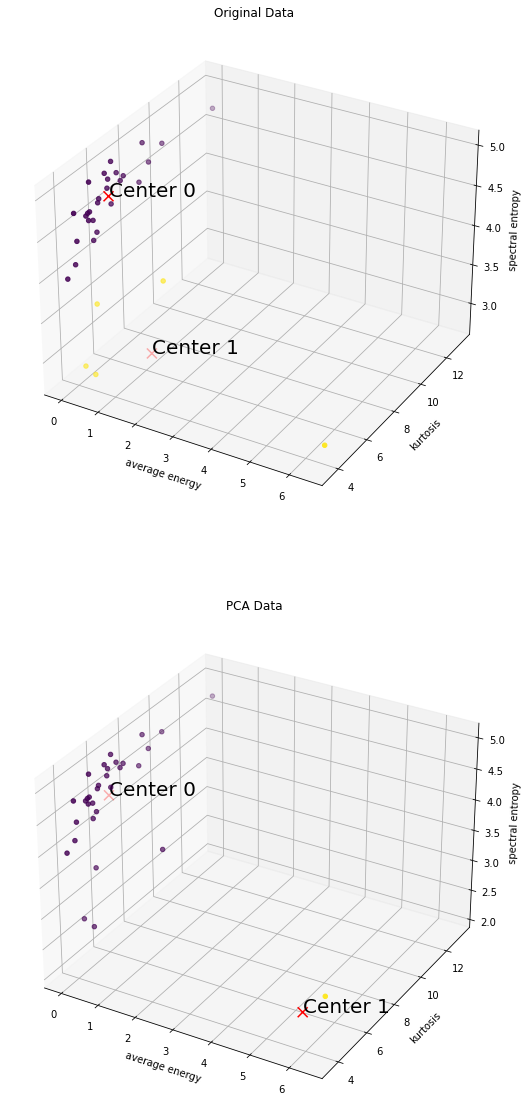

In [161]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = labels
        color_map_labels = labels
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    # Annotate cluster centers with their positions
    for j, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {j}', color='black', fontsize=20)

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

Reconstructed nodes by group:


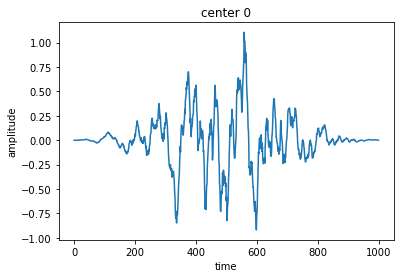

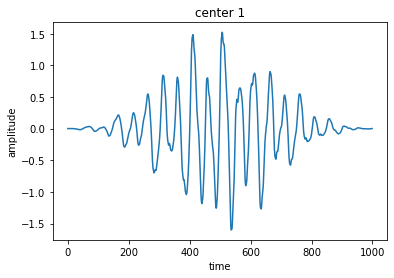

In [162]:
plot.plot_reconstructions_by_group(tr_ob, labels_pca, no_clusters)

In [163]:
basenode = tr_ob.get_level(0)[0]
basenode.level_entropy

5.832965039297175

(0.0, 781250.0)


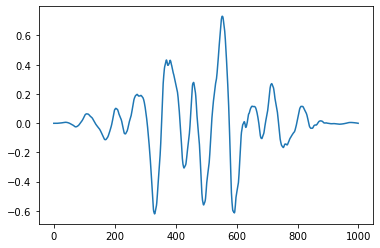

(781250.0, 1562500.0)


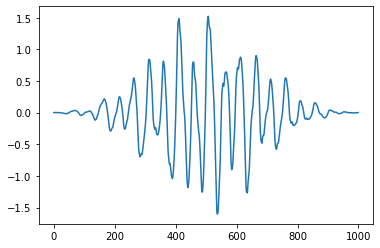

(2343750.0, 3125000.0)


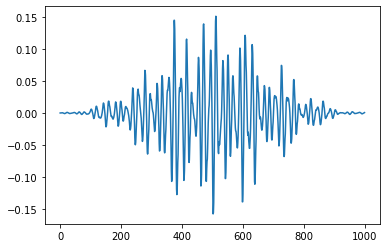

(1562500.0, 2343750.0)


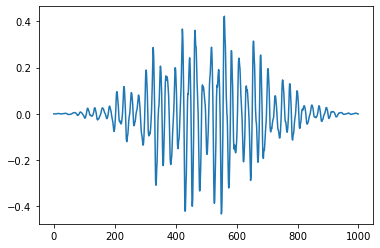

(3125000.0, 3906250.0)


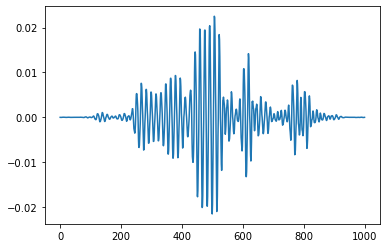

In [164]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [1]
    for i, (node, assignment) in enumerate(zip(tr_ob.get_level(), labels)):
        if assignment in plot_centres:
            print(node.frequency_range)
            rec = inv.inv_dwpt(tr_ob, node.level, nodes=node)
            plt.plot(rec)
            plt.show()

In [165]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["energy"] > THR_Factor * np.max(data_train["energy"])
]
harmonics_data = harmonics_data.sort_values(by="energy", ascending=False)

KeyError: 'energy'

In [ ]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest factor"] > THR_Factor * np.max(data_train["crest factor"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

In [ ]:
print(len(harmonics_data["energy"]))
harmonics_data["frequency range"].values.tolist()

1


[('3.125e-2', '4.688e-2')]

<AxesSubplot:>

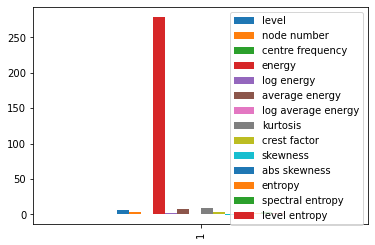

In [ ]:
harmonics_data.plot.bar()

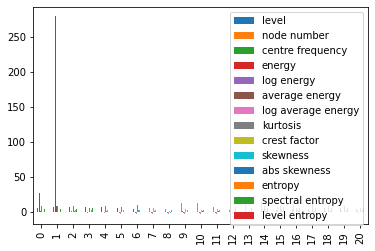

In [ ]:
transient_data.plot.bar()
plt.show()